# Classification Models: From Binary Diagnosis to Multiclass Prediction

---

> ### 📋 Practice Exercise. Not Graded.
> This is a **practice assignment** for self-assessment. The marks shown throughout are **indicative only**. They tell you where to spend your effort and where you might need more practice. **None of these marks count towards your final grade.**
>
> Attempt every section. Compare your results. Revisit what trips you up.

---

## What You Will Build

Two classifiers, two datasets, one progression from simple to complex.

| Part | Dataset | Task | Primary Metric |
|------|---------|------|----------------|
| **Part 1** | Breast Cancer (sklearn) | Binary: Malignant vs Benign | Recall (Sensitivity) |
| **Part 2** | Wine (sklearn) | Multiclass: 3 wine cultivars | Macro-averaged F1-Score |

**Indicative Marks: 100** (Part 1: 55 | Part 2: 45)

### Before You Start
- Complete all cells marked with `# TODO`.
- Markdown cells marked **[Your Answer]** need written responses. Don't skip them.
- Run `Runtime > Restart and run all` before reviewing. The notebook should execute top to bottom without errors.
- Use `random_state=42` wherever a function accepts it. This keeps your results reproducible.


---
# PART 1: Binary Classification, Breast Cancer Prediction

## Context

Early detection of malignant tumours saves lives. In this part, you will build classifiers that predict whether a breast tumour is **malignant** or **benign** based on features computed from cell nuclei images.

**Why Recall matters here:** A false negative means telling a patient their tumour is benign when it is actually malignant. That is a missed cancer diagnosis. A false positive means an unnecessary follow-up test. Annoying, but survivable. The asymmetry is stark: we prioritise **recall for the malignant class** above everything else.

> **Clinical Constraint:** We want recall ≥ 0.95 for malignant cases, while keeping precision ≥ 0.60 (i.e., not flooding clinics with false alarms).


## Stage 1: Data and Package Loading

<font color="red">**[3 marks]**</font>

Load the Breast Cancer Wisconsin dataset from `sklearn.datasets`.

**What to do:**
- The libraries below are pre-imported. Review them, add anything else you need.
- Load the dataset using `load_breast_cancer()`
- Convert it to a DataFrame with proper column names
- Separate features (`X`) and target (`y`)

> **Watch out:** In the raw dataset, `0 = malignant` and `1 = benign`. Since `recall_score` defaults to `pos_label=1`, we need malignant to be 1. **Remap the target** with `y = 1 - data.target`.


In [1]:
# Pre-imported libraries. Review these, add what you need below.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score,
                             precision_recall_curve)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

import warnings
warnings.filterwarnings('ignore')


In [2]:
# Load the breast cancer dataset and convert to DataFrame
data = load_breast_cancer()
### CODE HERE ###
data_cancer_df = pd.DataFrame(data.data, columns=data.feature_names)
data_cancer_df['target'] = data.target
data_cancer_df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


To verify original dataset value of malignant and benign

In [3]:
data.target_names

array(['malignant', 'benign'], dtype='<U9')

In [4]:
# Separate features and target, remap so malignant = 1
### CODE HERE ###
X = data_cancer_df.drop('target', axis=1)
y = 1 - data.target # remaping ,here earlier 0 became 1[Malignant] and 1 became 0

## Stage 2: Data Understanding

<font color="red">**[8 marks]**</font>

Before building any model, understand the data.


### 2.1 Basic Inspection <font color="red">[2 marks]</font>

Display the first few rows, check the shape, data types, and confirm there are no missing values.


In [5]:
print("****** Check first few rows ******** ")
X.head()


****** Check first few rows ******** 


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
y[:5]


array([1, 1, 1, 1, 1])

In [7]:
# Check shape, data types, and missing values
### CODE HERE ###
print("******** Check shapes of X and y ******")
print(X.shape)
print(y.shape)
print("\n")

******** Check shapes of X and y ******
(569, 30)
(569,)




In [8]:
print("******** Check data types *********")
print(X.dtypes)
print("\n")

******** Check data types *********
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave point

In [9]:
print(y.dtype)

int64


In [10]:
print("********* Check missing values ********")
print(X.isnull().sum())
print(pd.Series(y).isnull().sum())

********* Check missing values ********
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64
0


### 2.2 Summary Statistics <font color="red">[2 marks]</font>

Generate descriptive statistics. Pay attention to the **scale differences** across features. Some features range in the hundreds, others below 1. This matters for your preprocessing choices.


In [11]:
# Summary statistics
# Note the scale differences: mean radius is ~14, mean area is ~654, mean fractal dimension is ~0.06
### CODE HERE ###

descriptive_stats = X.describe().T[['mean', 'std', 'min', 'max']]

# Display the statistics
print(descriptive_stats)


                               mean         std         min         max
mean radius               14.127292    3.524049    6.981000    28.11000
mean texture              19.289649    4.301036    9.710000    39.28000
mean perimeter            91.969033   24.298981   43.790000   188.50000
mean area                654.889104  351.914129  143.500000  2501.00000
mean smoothness            0.096360    0.014064    0.052630     0.16340
mean compactness           0.104341    0.052813    0.019380     0.34540
mean concavity             0.088799    0.079720    0.000000     0.42680
mean concave points        0.048919    0.038803    0.000000     0.20120
mean symmetry              0.181162    0.027414    0.106000     0.30400
mean fractal dimension     0.062798    0.007060    0.049960     0.09744
radius error               0.405172    0.277313    0.111500     2.87300
texture error              1.216853    0.551648    0.360200     4.88500
perimeter error            2.866059    2.021855    0.757000    2

### 2.3 Class Distribution <font color="red">[2 marks]</font>

How many malignant vs benign cases are there? Visualise this with a bar plot.


0    357
1    212
Name: count, dtype: int64


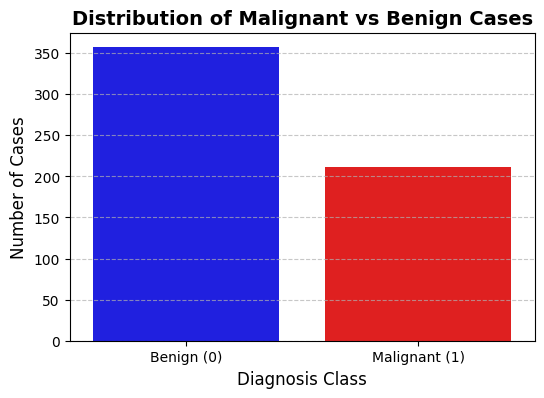

In [12]:
# Class distribution after remapping
### CODE HERE ###
# Calculate case counts

print(pd.Series(y).value_counts())

# Generate the bar plot
plt.figure(figsize=(6, 4))
sns.countplot(x=y, palette=['blue', 'red'])

# Aesthetics
plt.title('Distribution of Malignant vs Benign Cases', fontsize=14, fontweight='bold')
plt.xlabel('Diagnosis Class', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.xticks(ticks=[0, 1], labels=['Benign (0)', 'Malignant (1)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

### 2.4 Feature Distributions <font color="red">[2 marks]</font>

Pick 4-6 features and plot their distributions using histograms or boxplots. Look for skewness, outliers, and whether the two classes separate visually on any feature.


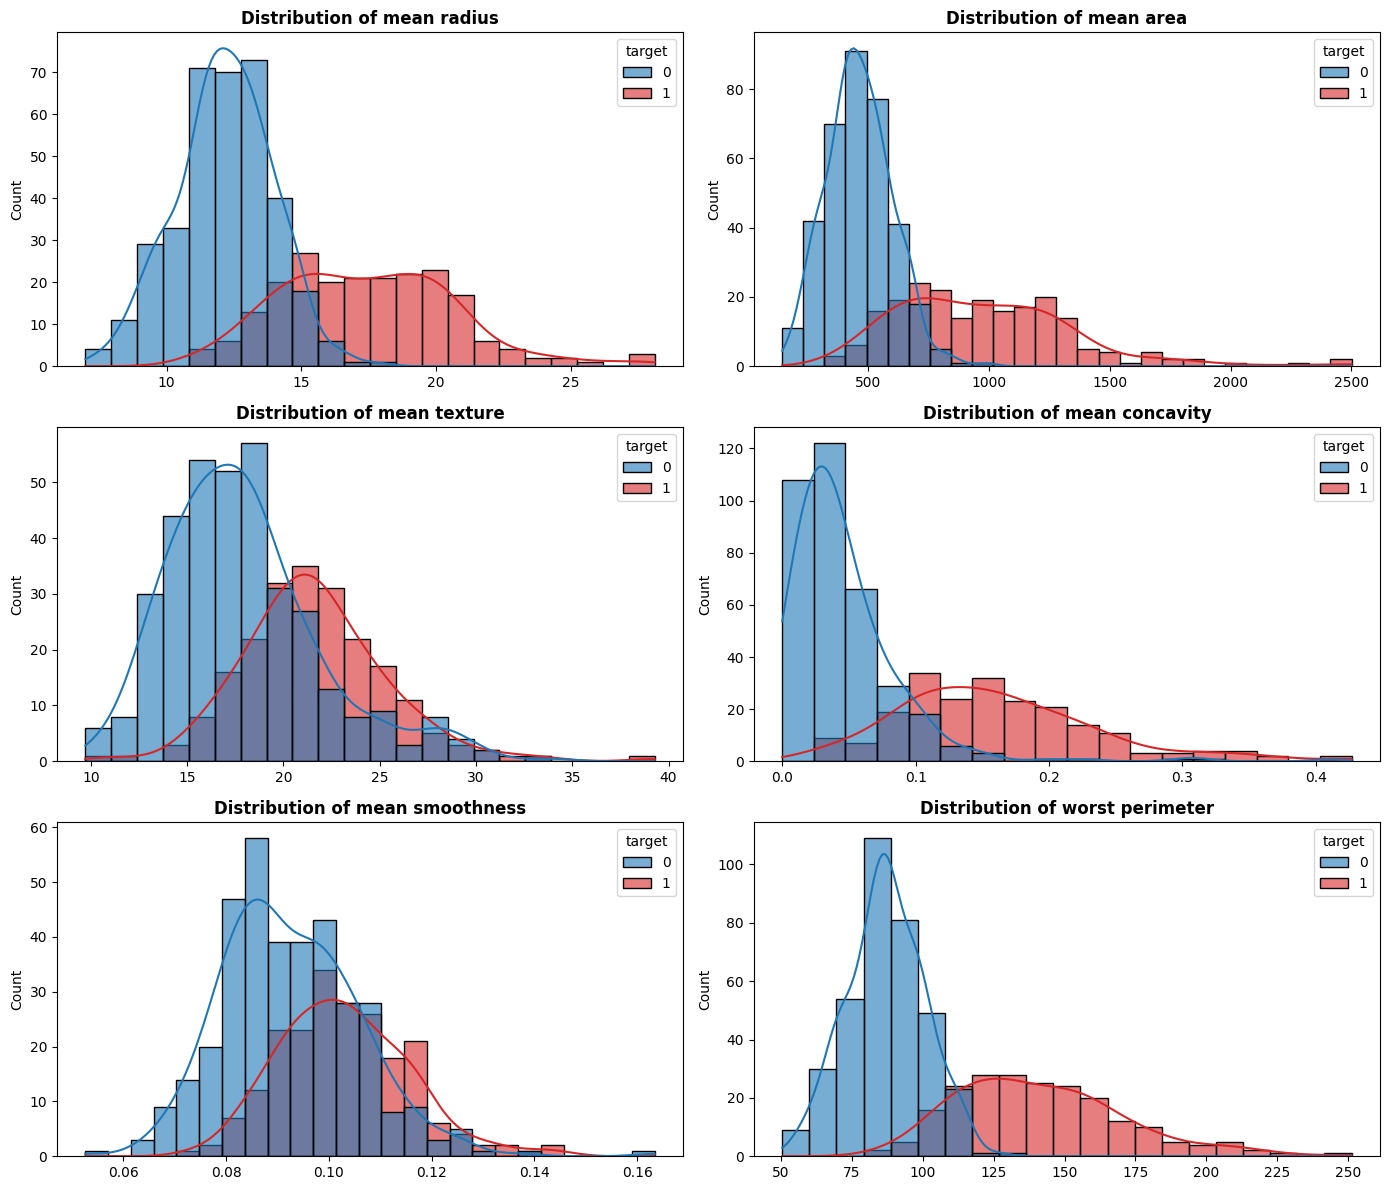

In [13]:
# Feature distributions for 6 selected features, coloured by class
### CODE HERE ###
# Select the features to plot
selected_features = ['mean radius', 'mean area', 'mean texture', 'mean concavity', 'mean smoothness', 'worst perimeter']

# Set up the matplotlib grid
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 12))
axes = axes.flatten() # Flatten to 1D array for easy iteration

# Combine X and y temporarily for plotting
plot_df = X[selected_features].copy()
plot_df['target'] = y

# hue = 'target' : coloring the histogram bars based on the distinct categories
# multiple: When using hue, how should overlapping bars be handled?
# multiple="layer": (Default) Overlaps the bars transparently. multiple="dodge": Places the bars side-by-side (like a bar chart)
# kde = True : Superimposes a Kernel Density Estimate line over the histogram. This adds a smooth curve tracking the overall shape of the data distribution

for i, col in enumerate(selected_features):
    sns.histplot(data=plot_df, x=col, hue='target', kde=True, ax=axes[i],
                 palette=['#1f77b6', '#d62728'], multiple='layer', alpha=0.6)
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

### ✍️ Interpretation Checkpoint

**[Your Answer]:** Answer these questions in 2-3 sentences each:
1. Is the dataset balanced? How might imbalance affect model training?
2. Do the features have similar scales? What does this mean for models like KNN and SVM?
3. Why is recall a better primary metric than accuracy for this problem?
4. Why must we fit the scaler on training data only and not on the full dataset? What information from the test set would leak into training if we did?


*Write your answers here:*

1. No dataset is not balanced. 62% values are of type Benign , whereas rest 38% are of Malignant. This may affect to perfectly understand Malignant related feature.Model may not havce sufficient data to perfectly learn overall scenarios. In case of mecdical , false negative can be critical. Due to this imbalance ,model may miss malignant cases.

2. From describe() , we can observe mean area ,area error,worst perimeter,worst area - these has higher range.
Other range are less , most are within 1. So for KNN/SVM - which calculate based on distance within vectors - other features will be ignored. We should scale all these so that all features get equal importance

3. Recall (also known as Sensitivity or True Positive Rate) measures what fraction of all actual positive cases the model manages to find correctly.
Recall = TP / (TP+FN).
Whereas Accuracy measures the percentage of all predictions that a model gets correct. Accuracy = (TP +TN)/(TP+TN+FP+FN)
We can see , Recall punishes if model have more False negative. In this medical issue( breast cancer ) , we expect a model which has least False negative. So Recall is better metrics for these kind of use-cases.

4. In machine learning, you must fit a scaler strictly on the training data to preserve the core purpose of a test set: simulating how your model performs on entirely unseen data.If we include the test set in this step, global data statistics leak into the training process.
StandardScaler (Standardisation): Leaks the exact mean and standard deviation of the test data. The training data values are shifted and scaled based on averages that include "future" data points.
So we should only do fit_transform() on training data whereas only transform() for test data.
fit_transform : z(i) = ( x(i) - Mu)/ Sigma => where Mu => Mean of the dataaset
Sigma = Variance of the dataset, z(i) is the scaled value for existing feature x(i). So in fit_transform() , Mu and sigma should be from train data , without infiltrating test unseen data.
transform() also will use same Mu and Sigma , just for scaling. This way , test dataset and spread will not leak.


## Stage 3: Data Preprocessing and Preparation

<font color="red">**[7 marks]**</font>


### 3.1 Missing Value Audit <font color="red">[1 mark]</font>

Confirm no missing values exist. If any do, handle them with median imputation.


In [14]:
# Missing value audit
### CODE HERE ###
#already isnull().sum() been checked , here info() also can be seen that no missing values and data types. As all the datatype are of float / int type
# and no object , we dont need to make those in integer ( one hot encoding )
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [15]:
pd.Series(y).info()

<class 'pandas.core.series.Series'>
RangeIndex: 569 entries, 0 to 568
Series name: None
Non-Null Count  Dtype
--------------  -----
569 non-null    int64
dtypes: int64(1)
memory usage: 4.6 KB


### 3.2 Train-Test Split <font color="red">[2 marks]</font>

Split into 70% training and 30% test using **stratified sampling** to preserve the class ratio to mitigate any slight class imbalance. Use `random_state=42`.


In [16]:
# Stratified train-test split
### CODE HERE ###
X_train_bc, X_test_bc, y_train_bc, y_test_bc  = train_test_split(
    X, y,
    # ↳ Reserve 30% of the examples for testing; the remaining 70% are used for training.
    test_size=0.3,
    # ↳ Fix the random split so repeated runs produce the same train/test partition.
    random_state=42,
    stratify = y
    # This to preserve original class proportion in split data
)

### 3.3 Feature Scaling <font color="red">[2 marks]</font>

Apply `StandardScaler`. **Fit the scaler on training data only**, then transform both train and test sets. If you fit on the full dataset, the scaler learns the mean and standard deviation of the test data, which inflates your results. That is data leakage.

> **Note:** Decision Trees split on thresholds and don't need scaling. But for consistency here, we scale for all models.


In [17]:
# Feature scaling: fit on train only, transform both
### CODE HERE ###

#  Initialize the scaler object
scaler = StandardScaler()

# Scale the data
# Fit the scaler using ONLY the training features, then transform them
X_train_bc = scaler.fit_transform(X_train_bc)

# Transform the testing features using the already fitted scaler
X_test_bc = scaler.transform(X_test_bc)

### 3.4 Confirm Prepared Data <font color="red">[2 marks]</font>

Print shapes of your final training and test sets. Verify the class distribution is preserved in both.


In [18]:
# Confirm prepared data
### CODE HERE ###
X_train_bc.shape, X_test_bc.shape, y_train_bc.shape, y_test_bc.shape

((398, 30), (171, 30), (398,), (171,))

## Helper: Evaluation Function

You will evaluate many models. Rather than copy-pasting the same five lines every time, define a reusable function. Call it throughout Stages 4-6.


In [19]:
# write a evaluate function to test. THis will be deleted , as actual one written above
def evaluate(y_test, y_pred, target_name=None):
    """
    Evaluates model predictions by showing accuracy, recall, precision, F1-score,
    confusion matrix, classification report, ROC curve, and Precision-Recall curve.
    """
    # If target_name is a numpy array, list, or other collection, join elements into a readable string
    if isinstance(target_name, (list, np.ndarray, pd.Series)):
        formatted_name = ", ".join(str(name).upper() for name in target_name)
    elif target_name is not None:
        formatted_name = str(target_name).upper()
    else:
        formatted_name = "UNKNOWN"

    print("=" * 60)
    print(f"       EVALUATION REPORT FOR: {formatted_name} ")
    print("=" * 60)

    # 1. Calculate and display core scalar metrics
    acc = accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred , average= 'macro')
    prec = precision_score(y_test, y_pred , average= 'macro')
    f1 = f1_score(y_test, y_pred , average= 'macro')

    print(f"Accuracy Score  : {acc:.4f}")
    print(f"Precision Score : {prec:.4f}")
    print(f"Recall Score    : {rec:.4f}")
    print(f"F1 Score        : {f1:.4f}\n")

    # 2. Display Classification Report & Confusion Matrix
    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=target_name))


## How GridSearchCV Works

If you haven't used `GridSearchCV` before, read this before moving on.

`GridSearchCV` automates hyperparameter tuning. You give it a set of parameter values to try, and it trains a model for every combination, scores each one using cross-validation, and tells you which combination won.

You can refer to the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

Here is the pattern you will repeat for every model below:

```python
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# 1. Define what parameter values to try
param_grid = {'C': [0.1, 1, 10]}

# 2. Set up GridSearchCV
grid = GridSearchCV(
    estimator=LogisticRegression(random_state=42, max_iter=10000),
    param_grid=param_grid,
    scoring='recall',   # what metric to optimise
    cv=5,               # 5-fold cross-validation on training data
    n_jobs=-1            # use all CPU cores
)

# 3. Fit on training data
grid.fit(X_train_scaled, y_train)

# 4. Check results
print("Best parameters:", grid.best_params_)
print("Best CV recall:", grid.best_score_)
best_model = grid.best_estimator_

# 5. Predict on test set
y_pred = best_model.predict(X_test_scaled)
```

Every model below follows the same five steps. The only things that change are the estimator and the parameter grid.


## Stage 4: Model Training, Hyperparameter Tuning, and Evaluation

<font color="red">**[23 marks]**</font>

Train **four classifiers**, tune them, evaluate each one.

For each model:
1. Define the parameter grid
2. Run `GridSearchCV` with `scoring='recall'`, `cv=5`
3. Print the best parameters
4. Predict on the test set using the best estimator
5. Evaluate using `evaluate_model()`

> We use `scoring='recall'` because our goal is to catch malignant cases. Accuracy is misleading when classes are imbalanced.


### 4.1 Logistic Regression (Baseline) <font color="red">[5 marks]</font>

Logistic Regression with `class_weight='balanced'` to handle class imbalance.

**Hyperparameters to tune:**
- `C`: Regularisation strength. Try `[0.01, 0.1, 1, 10, 100]`
- Set `max_iter=10000` and `random_state=42`


In [20]:
# Logistic Regression with GridSearchCV
### CODE HERE ###
# 1. Define what parameter values to try
lr_param_grid = {'C': [0.01, 0.1, 1, 10, 100]}
# 2 . Set up GridSearchCV for LogisticRegression
lr_grid_bc = GridSearchCV(
    estimator=LogisticRegression(class_weight='balanced', random_state=42, max_iter=10000),
    param_grid= lr_param_grid,
    scoring='recall',   # what metric to optimise
    cv=5,               # 5-fold cross-validation on training data
    n_jobs=-1            # use all CPU cores
)

# 3. Fit on training data
lr_grid_bc.fit(X_train_bc, y_train_bc)

# 4. Check results
print("Best parameters:", lr_grid_bc.best_params_)
print("Best CV recall:", lr_grid_bc.best_score_)
best_model_bc = lr_grid_bc.best_estimator_

# 5. Predict on test set
y_pred_lr = best_model_bc.predict(X_test_bc)

Best parameters: {'C': 10}
Best CV recall: 0.9388505747126438


In [21]:
new_target_names = list(data.target_names[::-1])
new_target_names

[np.str_('benign'), np.str_('malignant')]

In [22]:
# Evaluate LR on test set
### CODE HERE ###

# Now you can safely pass either a single string or your array of target names:
evaluate(y_test_bc, y_pred_lr, target_name=new_target_names)

       EVALUATION REPORT FOR: BENIGN, MALIGNANT 
Accuracy Score  : 0.9708
Precision Score : 0.9736
Recall Score    : 0.9641
F1 Score        : 0.9685

Classification Report:
              precision    recall  f1-score   support

      benign       0.96      0.99      0.98       107
   malignant       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



### 4.2 K-Nearest Neighbours (KNN) <font color="red">[6 marks]</font>

[KNN](https://scikit-learn.org/stable/modules/neighbors.html) classifies a sample by majority vote of its nearest neighbours. Sensitive to feature scale, which is why we scaled the data.

**Hyperparameters to tune:**
- `n_neighbors`: Try `[3, 5, 7, 9, 11, 15]`
- `weights`: Try `['uniform', 'distance']`. Uniform gives equal votes. Distance gives closer neighbours more influence.

> Think about it: if malignant samples are sparse in a local neighbourhood, why might `weights='distance'` help?


In [23]:
# KNN with GridSearchCV
### CODE HERE ###

knn_parameters_grid = [{'n_neighbors':[3,5,7,9,11,15]},
                   {'weights': ['uniform','distance']},]
knn = KNeighborsClassifier()
grid_knn = GridSearchCV(knn, knn_parameters_grid, cv=5, scoring='recall',n_jobs= -1)
grid_knn.fit(X_train_bc, y_train_bc)

# Check result
print("Best parameters:", grid_knn.best_params_)
print("Best CV recall:", grid_knn.best_score_)
best_model_knn_bc = grid_knn.best_estimator_

Best parameters: {'n_neighbors': 7}
Best CV recall: 0.925287356321839


In [24]:
# Evaluate KNN on test set
### CODE HERE ###

# predict on test set
y_pred_knn = best_model_knn_bc.predict(X_test_bc)

# evaluate on test set
evaluate(y_test_bc, y_pred_knn, target_name=new_target_names)

       EVALUATION REPORT FOR: BENIGN, MALIGNANT 
Accuracy Score  : 0.9649
Precision Score : 0.9735
Recall Score    : 0.9531
F1 Score        : 0.9618

Classification Report:
              precision    recall  f1-score   support

      benign       0.95      1.00      0.97       107
   malignant       1.00      0.91      0.95        64

    accuracy                           0.96       171
   macro avg       0.97      0.95      0.96       171
weighted avg       0.97      0.96      0.96       171



### 4.3 Decision Tree <font color="red">[6 marks]</font>

[Decision Trees](https://scikit-learn.org/stable/modules/tree.html) split features at thresholds. Without constraints, they memorise training data perfectly and fail on new data. That is overfitting.

**Hyperparameters to tune:**
- `max_depth`: Try `[3, 5, 7, 10, None]`. `None` means no limit.
- `min_samples_split`: Try `[2, 5, 10]`
- `min_samples_leaf`: Try `[1, 2, 4]`
- Use `class_weight='balanced'` and `random_state=42`


In [25]:
# Decision Tree with GridSearchCV
### CODE HERE ###
parameters_grid_dt = [{'max_depth':[3,5,7,10,None]},
                      {'min_samples_split': [2,5,10]},
                      {'min_samples_leaf':[1,2,4]},
                      ]
dt = DecisionTreeClassifier(random_state = 42, class_weight='balanced')

grid_srchcv_dt = GridSearchCV(dt,param_grid=parameters_grid_dt, scoring='accuracy',cv = 5)
grid_srchcv_dt.fit(X_train_bc, y_train_bc)

# Check result
print("Best parameters:", grid_srchcv_dt.best_params_)
print("Best CV recall:", grid_srchcv_dt.best_score_)
best_model_dt_bc = grid_srchcv_dt.best_estimator_

Best parameters: {'max_depth': 3}
Best CV recall: 0.921867088607595


In [26]:
# Evaluate Decision Tree on test set
### CODE HERE ###
print(f"Best Estimator : {grid_srchcv_dt.best_estimator_}")

#predict on test set
y_pred_dt = best_model_dt_bc.predict(X_test_bc)

# evaluate on test set
evaluate(y_test_bc, y_pred_dt, target_name=new_target_names)

Best Estimator : DecisionTreeClassifier(class_weight='balanced', max_depth=3, random_state=42)
       EVALUATION REPORT FOR: BENIGN, MALIGNANT 
Accuracy Score  : 0.9064
Precision Score : 0.9280
Recall Score    : 0.8781
F1 Score        : 0.8947

Classification Report:
              precision    recall  f1-score   support

      benign       0.88      0.99      0.93       107
   malignant       0.98      0.77      0.86        64

    accuracy                           0.91       171
   macro avg       0.93      0.88      0.89       171
weighted avg       0.91      0.91      0.90       171



### 4.4 Support Vector Machine (SVM) <font color="red">[6 marks]</font>

[SVMs](https://scikit-learn.org/stable/modules/svm.html) find the hyperplane that separates classes with the widest margin. With kernel functions, they can model non-linear boundaries.

**Hyperparameters to tune:**
- `C`: Try `[0.1, 1, 10]`
- `kernel`: Try `['linear', 'rbf']`. Linear for linearly separable data, RBF for non-linear.
- `gamma`: Try `['scale', 'auto']` (matters for RBF kernel)
- Use `class_weight='balanced'`, `random_state=42`, and `probability=True`

> **Why `probability=True`?** We need `predict_proba()` for threshold tuning in Stage 6.


In [27]:
# SVM with GridSearchCV
### CODE HERE ###
svm = SVC(class_weight='balanced',random_state=42,probability = True)

parameters_grid_svm = [{'C':[0.1,1,10]},
                      {'kernel': ['linear','rbf']},
                      {'gamma':['scale','auto']},
                      ]
grid_srchcv_svm = GridSearchCV(svm,param_grid=parameters_grid_svm, scoring='accuracy',cv = 5)
grid_srchcv_svm.fit(X_train_bc, y_train_bc)

#Check result
print("Best parameters:", grid_srchcv_svm.best_params_)
print("Best CV recall:", grid_srchcv_svm.best_score_)
best_model_svm_bc = grid_srchcv_svm.best_estimator_

Best parameters: {'C': 10}
Best CV recall: 0.9697151898734176


In [28]:
# Evaluate SVM on test set
### CODE HERE ###
print(f"Best Estimator : {grid_srchcv_svm.best_estimator_}")

# predict on test set
y_pred_svm = best_model_svm_bc.predict(X_test_bc)

# evaluate on test set
evaluate(y_test_bc, y_pred_svm, target_name=new_target_names)

Best Estimator : SVC(C=10, class_weight='balanced', probability=True, random_state=42)
       EVALUATION REPORT FOR: BENIGN, MALIGNANT 
Accuracy Score  : 0.9708
Precision Score : 0.9736
Recall Score    : 0.9641
F1 Score        : 0.9685

Classification Report:
              precision    recall  f1-score   support

      benign       0.96      0.99      0.98       107
   malignant       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



## Stage 5: Model Comparison

<font color="red">**[9 marks]**</font>


### 5.1 Build a Comparison Table <font color="red">[3 marks]</font>

Create a DataFrame comparing all four models on the **test set**:
- Accuracy
- Recall (for malignant class)
- Precision (for malignant class)
- F1-Score (for malignant class)
- Number of False Negatives (from confusion matrix)

> **Hint:** A false negative is a malignant case predicted as benign. In the confusion matrix, it sits at position `[1][0]` when malignant = 1.


In [29]:
# Comparison table for all 4 models
### CODE HERE ###
bc_results = pd.DataFrame(
    {
        'Model': [
            'Logistic Regression',
            'KNN',
            'Decision Tree',
            'SVM',
        ],
        'Accuracy': [
            accuracy_score(y_test_bc, y_pred_lr),
            accuracy_score(y_test_bc, y_pred_knn),
            accuracy_score(y_test_bc, y_pred_dt),
            accuracy_score(y_test_bc, y_pred_svm),
        ],
        'Precision': [
            precision_score(y_test_bc, y_pred_lr),
            precision_score(y_test_bc, y_pred_knn),
            precision_score(y_test_bc, y_pred_dt),
            precision_score(y_test_bc, y_pred_svm),
        ],
        'Recall': [
            recall_score(y_test_bc, y_pred_lr),
            recall_score(y_test_bc, y_pred_knn),
            recall_score(y_test_bc, y_pred_dt),
            recall_score(y_test_bc, y_pred_svm),
        ],
        'F1-Score': [
            f1_score(y_test_bc, y_pred_lr),
            f1_score(y_test_bc, y_pred_knn),
            f1_score(y_test_bc, y_pred_dt),
            f1_score(y_test_bc, y_pred_svm),
        ],
        # Extracts row index 1, column index 0 from the confusion matrix
        'False Negatives (Malignant)': [
            confusion_matrix(y_test_bc, y_pred_lr)[1, 0],
            confusion_matrix(y_test_bc, y_pred_knn)[1, 0],
            confusion_matrix(y_test_bc, y_pred_dt)[1, 0],
            confusion_matrix(y_test_bc, y_pred_svm)[1, 0],
        ],
    }
)
print(bc_results.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1-Score  False Negatives (Malignant)
Logistic Regression  0.970760   0.983607 0.937500  0.960000                            4
                KNN  0.964912   1.000000 0.906250  0.950820                            6
      Decision Tree  0.906433   0.980000 0.765625  0.859649                           15
                SVM  0.970760   0.983607 0.937500  0.960000                            4


In [30]:
'''
• cm[0][0] (Top-Left): True Negatives (TN) → Actual 0, Predicted 0
• cm[0][1] (Top-Right): False Positives (FP) → Actual 0, Predicted 1
• cm[1][0] (Bottom-Left): False Negatives (FN) → Actual 1, Predicted 0
• cm[1][1] (Bottom-Right): True Positives (TP) → Actual 1, Predicted 1
'''
confusion_matrix(y_test_bc, y_pred_lr)

array([[106,   1],
       [  4,  60]])

### 5.2 Visualise Comparison <font color="red">[2 marks]</font>

Create a grouped bar chart comparing Recall and Precision across all four models.


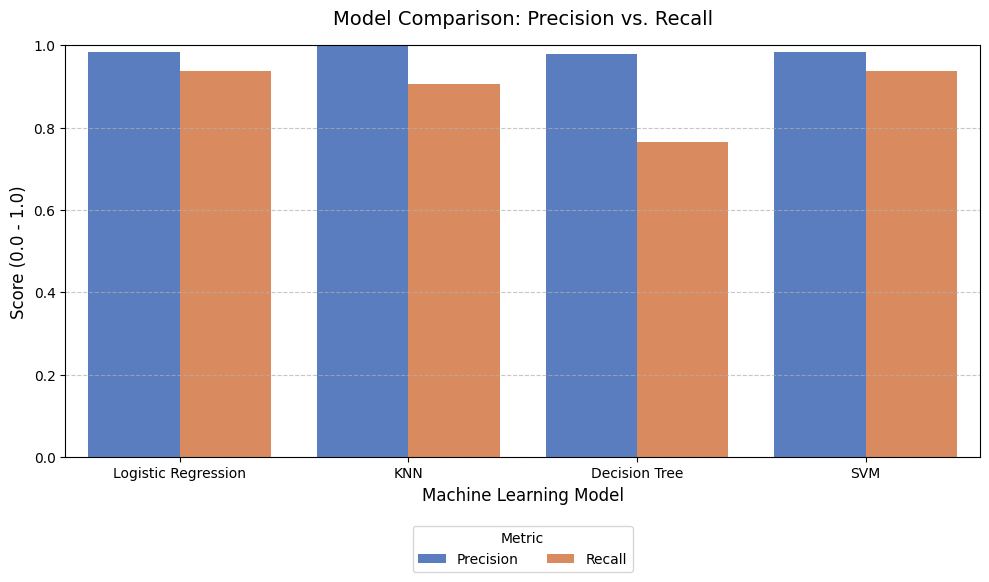

In [31]:
# Grouped bar chart: Recall and Precision
### CODE HERE ###

# 1. Melt the dataframe to convert 'Precision' and 'Recall' from columns to rows
df_melted = pd.melt(
    bc_results,
    id_vars=["Model"],
    value_vars=["Precision", "Recall"],
    var_name="Metric",
    value_name="Score",
)

# 2. Plot using Seaborn
plt.figure(figsize=(10, 6))
sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="muted")

# 3. Customize formatting and move legend below the plot
plt.title("Model Comparison: Precision vs. Recall", fontsize=14, pad=15)
plt.xlabel("Machine Learning Model", fontsize=12)
plt.ylabel("Score (0.0 - 1.0)", fontsize=12)
plt.ylim(0, 1.0)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Place legend below the chart
plt.legend(title="Metric", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)

plt.tight_layout()
plt.show()

### 5.3 Cross-Validation Stability <font color="red">[2 marks]</font>

For **all four models**, run 5-fold stratified [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html) on the **training set** using `cross_val_score` with `scoring='recall'`. Print the mean and standard deviation of recall for each.

> **Why this matters:** High recall on one split means nothing if the model collapses on another. Stability tells you whether you can trust the number.

> **A caveat:** You are running `cross_val_score` on already-tuned estimators. This is a quick stability check, not a substitute for nested cross-validation. Good enough for a practice exercise.


In [32]:
# Cross-validation stability for all 4 models
### CODE HERE ###
bcmodels = {
    'Logistic Regression': best_model_bc,
    'KNN': best_model_knn_bc,
    'Decision Tree': best_model_dt_bc,
    'SVM': best_model_svm_bc
}
for model_name, model in bcmodels.items():
    scores = cross_val_score(model, X_train_bc, y_train_bc, cv=5, scoring='recall')
    print(f"{model_name} - Recall Score: {scores.mean():.4f}, Std Dev: {scores.std():.4f}")

Logistic Regression - Recall Score: 0.9389, Std Dev: 0.0262
KNN - Recall Score: 0.9253, Std Dev: 0.0736
Decision Tree - Recall Score: 0.8908, Std Dev: 0.0855
SVM - Recall Score: 0.9317, Std Dev: 0.0693


### 5.4 Feature Importance <font color="red">[2 marks]</font>

Knowing *which features drive predictions* matters as much as the predictions themselves.

- Extract **feature importances** from your best Decision Tree (`.feature_importances_`) or **coefficients** from Logistic Regression (`.coef_[0]`)
- Plot the **top 10 most important features** as a horizontal bar chart


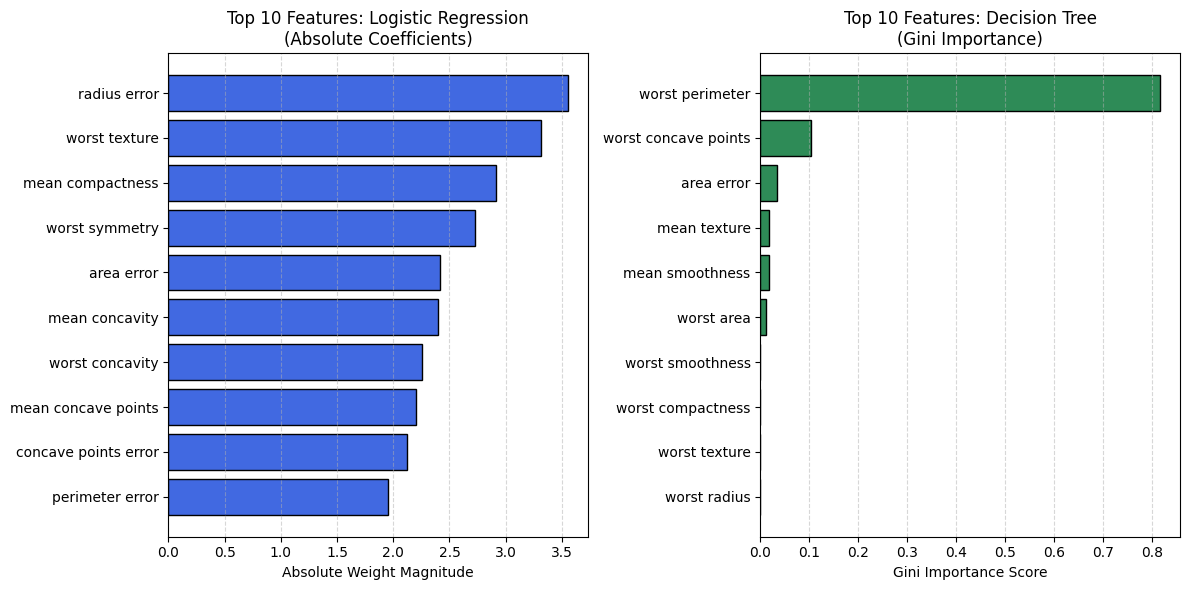

In [33]:
# Feature importance from Decision Tree
### CODE HERE ###

# Logistic Regression (Absolute magnitude of coefficients)
lr_weights = np.abs(best_model_bc.coef_[0])
# Decision Tree (Gini / Impurity importance)
dt_weights = best_model_dt_bc.feature_importances_

# build dataframe for sorting
df_lr = pd.DataFrame({'Feature': data.feature_names, 'Weight': lr_weights})
df_dt = pd.DataFrame({'Feature': data.feature_names, 'Weight': dt_weights})

# Extract top 10 features for each model
top10_lr = df_lr.sort_values(by='Weight', ascending=True).tail(10)
top10_dt = df_dt.sort_values(by='Weight', ascending=True).tail(10)

# 6. Plot both side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Panel 1: Logistic Regression
axes[0].barh(top10_lr['Feature'], top10_lr['Weight'], color='royalblue', edgecolor='black')
axes[0].set_title('Top 10 Features: Logistic Regression\n(Absolute Coefficients)')
axes[0].set_xlabel('Absolute Weight Magnitude')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Panel 2: Decision Tree
axes[1].barh(top10_dt['Feature'], top10_dt['Weight'], color='seagreen', edgecolor='black')
axes[1].set_title('Top 10 Features: Decision Tree\n(Gini Importance)')
axes[1].set_xlabel('Gini Importance Score')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Stage 6: Final Model Selection

<font color="red">**[5 marks]**</font>


### 6.1 Threshold Tuning <font color="red">[2 marks]</font>

By default, classifiers use a probability threshold of 0.5 to assign classes. For medical diagnosis, we can lower this threshold to catch more malignant cases (higher recall) at the cost of more false positives (lower precision).

**Steps:**
1. Create a **stratified validation split from your training data** (70/30 from `X_train_scaled`). Do not touch the test set for this.
2. Retrain your best model on the inner training portion
3. Get predicted probabilities on the validation portion using `predict_proba()`
4. Plot the **precision-recall curve**
5. Find a threshold where recall ≥ 0.95

> **Why not tune on the test set?** If you use the test set to pick a threshold, your final evaluation on that same test set is no longer honest. The test set becomes a tuning surface, and your reported metrics are optimistic.


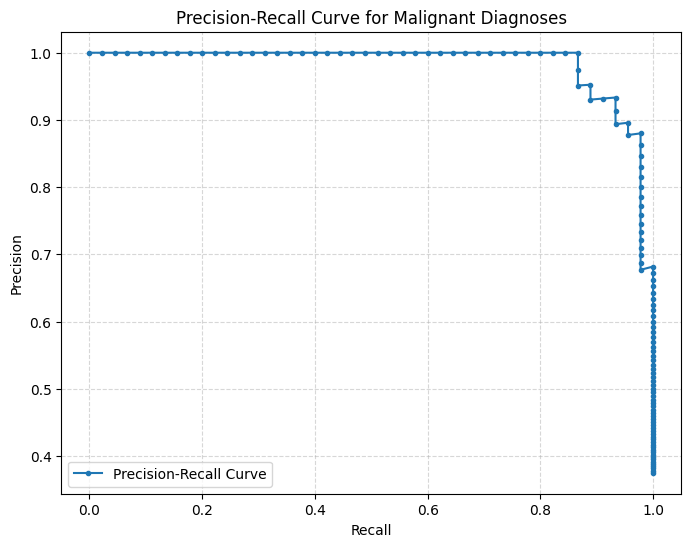

Threshold where recall >= 0.95: 0.0003


In [34]:
# Threshold tuning on a VALIDATION split (not test set)
# Step 1: Create inner split from training data
### CODE HERE ###
X_train_inner, X_val, y_train_inner, y_val = train_test_split(X_train_bc, y_train_bc, test_size=0.3, random_state=42, stratify=y_train_bc)

# Step 2: Retrain best model (SVM) on inner training set
### CODE HERE ###
best_model_svm_bc.fit(X_train_inner, y_train_inner)

# Step 3: Get predicted probabilities on validation set
### CODE HERE ###
y_val_pred_proba = best_model_svm_bc.predict_proba(X_val)[:, 1]

# Step 4: Plot precision-recall curve
### CODE HERE ###
precision, recall, thresholds = precision_recall_curve(y_val, y_val_pred_proba)
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.', label='Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for Malignant Diagnoses')
plt.grid(True,linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# Step 5: Find threshold where recall >= 0.95
### CODE HERE ###
threshold_95 = thresholds[np.argmax(recall >= 0.95)]
print(f"Threshold where recall >= 0.95: {threshold_95:.4f}")



### 6.2 Final Recommendation <font color="red">[3 marks]</font>

**[Your Answer]:** Answer the following. Cite specific numbers from your results.

1. Which model do you recommend and why? Reference its recall, false negative count, and cross-validation stability.
2. How many false negatives does it produce on the test set? Is this clinically acceptable?
3. What is one specific limitation of your analysis? (Not "more data." Be concrete, e.g., "the dataset has only 569 samples, which limits the reliability of cross-validation estimates.")


*Write your answers here:*

1. I will recommend Logis Regression based on current data in hand for our analysis. It has best recall value and False negative for Malignant is 4 , among the lowest of these 4 model. Even its recall and standard deviation (Recall Score: 0.9389, Std Dev: 0.0262) are also best among the models we worked on

2. 4 out of 64 Malignant cases are predicted as negative. So almost 6%. CLinically this should not be accepted. Ideal case less than 1% would be beneficial for use.

3. Firstly data are a bit skewed , has 357 beningn vs 212 malignant. Secondly there are many related data like 'mean area' , mean perimeter , mean radius. This will automatically give a relation which may not exist in other data.


---
# PART 2: Multiclass Classification, Wine Dataset

## Context

The Wine dataset contains chemical analysis results of wines from the same region of Italy, grown from **three different cultivars** (grape varieties). The task: predict the cultivar (class 0, 1, or 2) based on 13 chemical attributes like alcohol content, malic acid, and flavanoids.

**Why Macro-F1 matters here:** No single wine class is more "dangerous" to misclassify. All three matter equally. Macro-averaged F1-score treats each class the same regardless of size.


## Stage 1: Data and Package Loading

<font color="red">**[2 marks]**</font>

Load the Wine dataset from `sklearn.datasets`. Convert to a DataFrame. Separate features and target. Import `MLPClassifier`.


In [35]:
# Pre-imported for Part 2
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import load_wine

# Load wine dataset
wine_data = load_wine()
### CODE HERE ###
wine_df = pd.DataFrame(wine_data.data, columns=wine_data.feature_names)
wine_df['target'] = wine_data.target
wine_df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## Stage 2: Data Understanding

<font color="red">**[6 marks]**</font>


### 2.1 Basic Inspection <font color="red">[2 marks]</font>

Display the shape, first few rows, data types, and check for missing values.


In [36]:
# Inspect the wine dataset
### CODE HERE ###
# info() itself will give a summery of missing values , data types of the features and feature.
# We can observe in its output that all values are in float/int. Target is in integer
wine_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [37]:
wine_df.isnull().sum() # though confirmed in info() , just checking otherway to see missing values

,0
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


In [38]:
wine_df.shape

(178, 14)

Will check target values , to understand classification

In [39]:
wine_df['target'].value_counts()

,count
target,
1,71
0,59
2,48


### 2.2 Class Distribution <font color="red">[2 marks]</font>

How many wines in each class? Visualise with a bar plot.


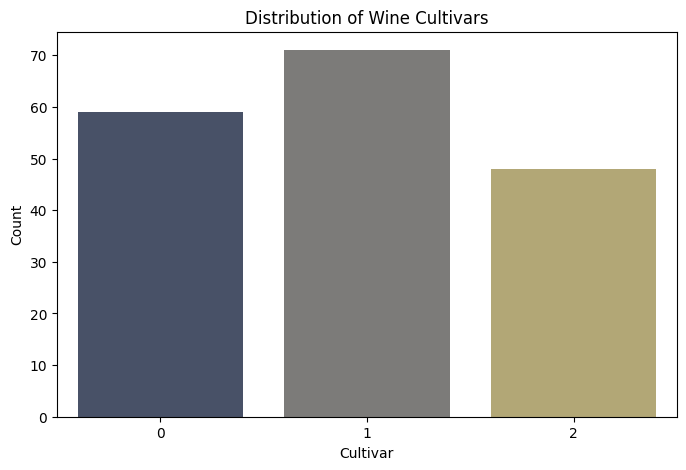

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

# Wine class distribution
plt.figure(figsize=(8,5))
#sns.countplot(x='target', data=wine_df)
count_df = wine_df['target'].value_counts().reset_index()
count_df.columns = ['target', 'count']
sns.barplot(x='target', y='count', data=count_df,palette='cividis')

plt.title('Distribution of Wine Cultivars')
plt.xlabel('Cultivar')
plt.ylabel('Count')
plt.show()

### 2.3 Feature Analysis <font color="red">[2 marks]</font>

Look at the feature ranges using `.describe()`. Some features range in the hundreds, others below 1. Then plot a **correlation heatmap** to see which features move together.


          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859              0.124453         0.572359   
min         0.9

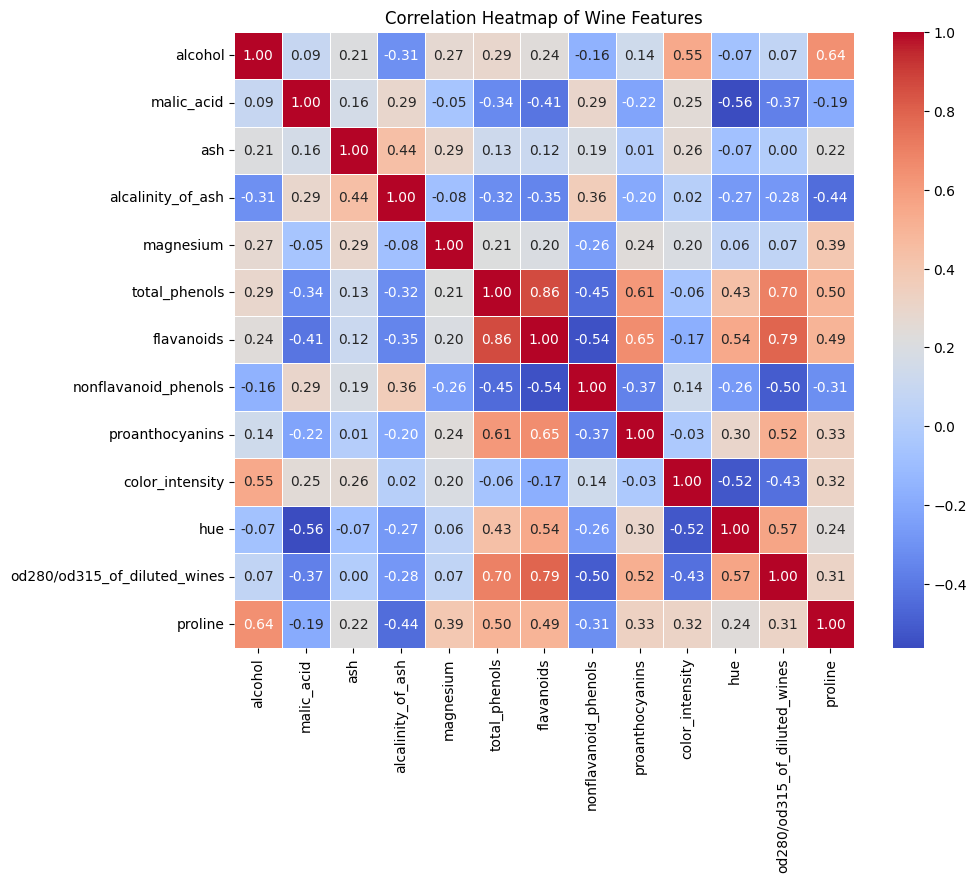

In [41]:
# Summary statistics
### CODE HERE ###
print(wine_df.describe())

# Correlation heatmap
### CODE HERE ###
# To see correlation matrix , seperate out 'target' and check within feature correlation
wine_features = wine_df.drop('target', axis=1)
plt.figure(figsize=(10, 8))
sns.heatmap(wine_features.corr(),
            annot=True,
            cmap='coolwarm', # blue = negative , red = positive
            fmt=".2f",       # format to 2 decimal places
            linewidths=0.5)  #add thin line between cells
plt.title('Correlation Heatmap of Wine Features')
plt.show()


### ✍️ Interpretation Checkpoint

**[Your Answer]:**
1. Are the three wine classes roughly balanced?
2. Looking at the feature ranges, do some features dominate others in scale? What does this imply for models like KNN and SVM?


*Write your answers here:*

1. Yes 3 wineclasses almost balanced (71 , 59 , 48) , with 1 type highest , then slighly less 0 type and then 2nd type

2. From describe() , we can observe 'proline'  , 'magnesium'  , 'alcalinity_of_ash' - these has higher range followed by 'alcohol' , 'color_intensity'. Other range are less , within 6. So for KNN/SVM - which calculate based on distance within vectors - other features will be ignored. We should scale all these so that all features get equal importance    


## Stage 3: Data Preprocessing

<font color="red">**[4 marks]**</font>


### 3.1 Split and Scale <font color="red">[2 marks]</font>

Stratified train-test split (70-30, `random_state=42`), then `StandardScaler` fit on training data only. Stratification for handling any slight class imbalance in the data.

> **Reminder:** Decision Trees don't need scaling, but KNN, SVM, MLP, and Logistic Regression all do. We scale for all models here.


In [42]:
# Stratified train-test split
### CODE HERE ###
X_train, X_test, y_train, y_test = train_test_split(wine_features, wine_df['target'], test_size=0.3, random_state=42, stratify=wine_df['target'])

In [43]:
# Scale features: fit on train, transform both
### CODE HERE ###
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



In [44]:
#Lets check data after scaling
temp_df_scaled = pd.DataFrame(X_train_scaled, columns=wine_features.columns)
temp_df_scaled.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,0.982686,-0.527640,0.173598,-1.087543,-0.727661,0.491455,0.791460,-0.596717,0.354587,0.255419,0.857462,0.437825,1.863180
1,0.957937,-0.745511,1.255504,0.839386,0.063252,1.131923,1.306553,-0.596717,1.343233,0.297587,1.032095,0.159563,1.749108
2,0.401078,-0.612894,1.777803,-1.235769,0.656436,0.491455,0.707363,-0.170491,-0.425924,-0.166255,0.595512,0.262081,0.429136
3,0.772317,-0.593949,-0.012937,-0.168547,0.392799,0.907759,1.243480,-1.193434,0.597412,0.803596,0.595512,0.408534,2.498722
4,-1.863482,0.107025,0.210905,0.098259,-0.266295,0.971806,0.822996,-0.340981,0.389276,-0.735516,-0.670576,1.155447,-0.401958


### 3.2 Verify Preparation <font color="red">[2 marks]</font>

Print shapes and class distributions for both splits.


In [45]:
# Verify preparation
### CODE HERE ###
print(X_train_scaled.shape)
print(y_train.shape)
print(X_test_scaled.shape)
print(y_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(124, 13)
(124,)
(54, 13)
(54,)
target
1    50
0    41
2    33
Name: count, dtype: int64
target
1    21
0    18
2    15
Name: count, dtype: int64


## Stage 4: Model Training and Hyperparameter Tuning

<font color="red">**[20 marks]**</font>

Train **five classifiers** on the wine dataset. Use `GridSearchCV` with `scoring='f1_macro'` and `cv=5` for each. Use the `evaluate_model()` helper from Part 1.

> **Key difference from Part 1:** We optimise for `f1_macro` instead of `recall`, because all classes matter equally.


### 4.1 Logistic Regression <font color="red">[3 marks]</font>

**Hyperparameters:**
- `C`: `[0.01, 0.1, 1, 10]`
- `max_iter`: `10000`
- `random_state`: `42`


In [46]:
# Logistic Regression for Wine
### CODE HERE ###
param_grid_lr = {'C': [0.01, 0.1, 1, 10]}
lr_model = LogisticRegression(max_iter=10000, random_state=42)
grid = GridSearchCV(lr_model, param_grid_lr, scoring='f1_macro', cv=5)
grid.fit(X_train_scaled, y_train)
best_model_lr_wd = grid.best_estimator_

#Predict on test set
y_pred_lr_wd = best_model_lr_wd.predict(X_test_scaled)
#evaluate_model(best_model,X_test_scaled,y_test,target_names = wine_data.target_names)

#Evaluate on test set
evaluate(y_test,y_pred_lr_wd,target_name = wine_data.target_names)

       EVALUATION REPORT FOR: CLASS_0, CLASS_1, CLASS_2 
Accuracy Score  : 1.0000
Precision Score : 1.0000
Recall Score    : 1.0000
F1 Score        : 1.0000

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      1.00      1.00        21
     class_2       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



In [47]:
grid.best_params_

{'C': 0.1}

### 4.2 K-Nearest Neighbours <font color="red">[3 marks]</font>

**Hyperparameters:**
- `n_neighbors`: `[3, 5, 7, 9, 11]`
- `weights`: `['uniform', 'distance']`


In [48]:
# KNN for Wine
### CODE HERE ###
knn_param_grid = {'n_neighbors': [3, 5, 7, 9, 11],
                  'weights': ['uniform', 'distance']}
knn_model = KNeighborsClassifier()
knn_grid = GridSearchCV(knn_model, knn_param_grid, scoring='f1_macro', cv=5)
knn_grid.fit(X_train_scaled, y_train)

best_knn_model_wd = knn_grid.best_estimator_

#predict on test set
y_pred_knn_wd = best_knn_model_wd.predict(X_test_scaled)
#Evaluate on test set
evaluate(y_test,y_pred_knn_wd,target_name = wine_data.target_names)


       EVALUATION REPORT FOR: CLASS_0, CLASS_1, CLASS_2 
Accuracy Score  : 0.9630
Precision Score : 0.9608
Recall Score    : 0.9683
F1 Score        : 0.9625

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      0.90      0.95        21
     class_2       0.88      1.00      0.94        15

    accuracy                           0.96        54
   macro avg       0.96      0.97      0.96        54
weighted avg       0.97      0.96      0.96        54



In [49]:
knn_grid.best_params_

{'n_neighbors': 11, 'weights': 'uniform'}

### 4.3 Decision Tree <font color="red">[3 marks]</font>

**Hyperparameters:**
- `max_depth`: `[3, 5, 7, 10, None]`
- `min_samples_split`: `[2, 5, 10]`
- `min_samples_leaf`: `[1, 2, 4]`
- `random_state`: `42`


In [50]:
# Decision Tree for Wine
### CODE HERE ###

dt_param_grid = {'max_depth': [3, 5, 7, 10, None],
                 'min_samples_split': [2, 5, 10],
                 'min_samples_leaf': [1, 2, 4]}
dt_model = DecisionTreeClassifier(random_state=42)
dt_grid = GridSearchCV(dt_model, dt_param_grid, scoring='f1_macro', cv=5)
dt_grid.fit(X_train_scaled, y_train)

best_dt_model_wd = dt_grid.best_estimator_
#predict on test set
y_pred_dt_wd = best_dt_model_wd.predict(X_test_scaled)
#Evaluate on test set
evaluate(y_test,y_pred_dt_wd,target_name = wine_data.target_names)


       EVALUATION REPORT FOR: CLASS_0, CLASS_1, CLASS_2 
Accuracy Score  : 0.9630
Precision Score : 0.9710
Recall Score    : 0.9593
F1 Score        : 0.9638

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      0.94      0.97        18
     class_1       0.91      1.00      0.95        21
     class_2       1.00      0.93      0.97        15

    accuracy                           0.96        54
   macro avg       0.97      0.96      0.96        54
weighted avg       0.97      0.96      0.96        54



In [51]:
dt_grid.best_params_

{'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 5}

### 4.4 Support Vector Machine <font color="red">[3 marks]</font>

**Hyperparameters:**
- `C`: `[0.1, 1, 10]`
- `kernel`: `['linear', 'rbf']`
- `gamma`: `['scale', 'auto']`
- `random_state`: `42`


In [52]:
# SVM for Wine
### CODE HERE ###
svm_param_grid = {'C': [0.1, 1, 10],
                  'kernel': ['linear', 'rbf'],
                  'gamma': ['scale', 'auto']}
svm_model = SVC(random_state=42)
svm_grid = GridSearchCV(svm_model, svm_param_grid, scoring='f1_macro', cv=5)
svm_grid.fit(X_train_scaled, y_train)

best_svm_model_wd = svm_grid.best_estimator_

#predict on test set
y_pred_svm_wd = best_svm_model_wd.predict(X_test_scaled)
#Evaluate on test set
evaluate(y_test,y_pred_svm_wd,target_name = wine_data.target_names)

       EVALUATION REPORT FOR: CLASS_0, CLASS_1, CLASS_2 
Accuracy Score  : 0.9815
Precision Score : 0.9848
Recall Score    : 0.9778
F1 Score        : 0.9808

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       0.95      1.00      0.98        21
     class_2       1.00      0.93      0.97        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



In [53]:
svm_grid.best_params_

{'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}

### 4.5 Multi-Layer Perceptron (MLP) <font color="red">[8 marks]</font>

The MLP is a neural network. Unlike the previous models, you control the **architecture**: how many layers, how many neurons per layer.

**Hyperparameters to tune:**
- `hidden_layer_sizes`: Try `[(50,), (100,), (50, 50), (100, 50)]`. Each tuple defines layer widths.
- `activation`: Try `['relu', 'tanh']`. The non-linear function at each neuron.
- `alpha`: Try `[0.0001, 0.001, 0.01]`. L2 regularisation to prevent overfitting.
- Set `max_iter=2000`, `random_state=42`, and `early_stopping=True`

> **What is early stopping?** It monitors validation performance during training and stops when performance plateaus. Without it, the network keeps training until it memorises the data.


In [54]:
# MLP for Wine
### CODE HERE ###
mlp_param_grid = {'hidden_layer_sizes': [(50,), (100,), (50, 50), (100,50)],
                  'activation': ['relu', 'tanh'],
                  'alpha': [0.0001, 0.001, 0.01]}

mlp_model = MLPClassifier(max_iter=2000, random_state=42, early_stopping=True)
mlp_grid = GridSearchCV(mlp_model, mlp_param_grid, scoring='f1_macro', cv=5)
mlp_grid.fit(X_train_scaled, y_train)



GridSearchCV(cv=5,
             estimator=MLPClassifier(early_stopping=True, max_iter=2000,
                                     random_state=42),
             param_grid={'activation': ['relu', 'tanh'],
                         'alpha': [0.0001, 0.001, 0.01],
                         'hidden_layer_sizes': [(50,), (100,), (50, 50),
                                                (100, 50)]},
             scoring='f1_macro')

In [55]:
mlp_grid.best_params_

{'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (100,)}

In [56]:
# Evaluate MLP on test set
### CODE HERE ###
best_mlp_model_wd = mlp_grid.best_estimator_

#predict on test set
y_pred_mlp_wd = best_mlp_model_wd.predict(X_test_scaled)
#Evaluate on test set
evaluate(y_test,y_pred_mlp_wd,target_name = wine_data.target_names)

       EVALUATION REPORT FOR: CLASS_0, CLASS_1, CLASS_2 
Accuracy Score  : 0.8519
Precision Score : 0.8720
Recall Score    : 0.8730
F1 Score        : 0.8506

Classification Report:
              precision    recall  f1-score   support

     class_0       0.78      1.00      0.88        18
     class_1       1.00      0.62      0.76        21
     class_2       0.83      1.00      0.91        15

    accuracy                           0.85        54
   macro avg       0.87      0.87      0.85        54
weighted avg       0.88      0.85      0.84        54



### ✍️ MLP Interpretation

**[Your Answer]:**
1. What architecture (hidden layer sizes) performed best? Why do you think that configuration won?
2. Did the MLP outperform the classical models? By how much in macro-F1?
3. What role does `alpha` (regularisation) play? What happens if it is set too high? Too low?


*Write your answers here:*

1. Grid search provided "{'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (100,)}" as best paramters. with one single 100 hidden layer nerons. 100 gave enough space to determine decision bounday for this small set ( 178 x 13 data).
tanh over relu - as many feature has -ve values , relu would have been 0 for this. While tanh covers -1 to +1 as its activation value , won this case.



2. No it does not outperform the classical model. Rather in current train/test split - macro-F1 is 0.8506 for MLP classifier. Whereas for other classical model
logistic regression : F1-Macro Score: 1.0000
KNN : F1-Macro Score: 0.9625
Decision tree : F1-Macro Score: 0.9638
SVM : F1-Macro Score: 0.9808

3. alpha value .0001 , with mild penalty right fitting curve.
It is used for L2 regularization ( weight decay ). During training , the model tried to minimise its prediction error. Alpha add a penalty to the loss function based.
If alphas is too high - the penalty for having large weight becomes massive , leads to underfitting. Perform poor both on training/test data
If alpha is too low - network faces no penalty for its weight sizes. Leads to overfitting. The model becomes highly sensitive to small fluctuations in the training dataset.


## Stage 5: Model Comparison

<font color="red">**[8 marks]**</font>


### 5.1 Comparison Table <font color="red">[3 marks]</font>

Create a DataFrame comparing all five models on the **test set**:
- Accuracy
- Macro-Precision
- Macro-Recall
- Macro-F1-Score


In [57]:
results=pd.DataFrame({
    "Model":[
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "SVM",
        "MLP"
    ],
    "Accuracy":[
        accuracy_score(y_test,y_pred_lr_wd),
        accuracy_score(y_test,y_pred_knn_wd),
        accuracy_score(y_test,y_pred_dt_wd),
        accuracy_score(y_test,y_pred_svm_wd),
        accuracy_score(y_test,y_pred_mlp_wd),
    ],
    "Macro-Precision":[
        precision_score(y_test,y_pred_lr_wd,average='macro'),
        precision_score(y_test,y_pred_knn_wd,average='macro'),
        precision_score(y_test,y_pred_dt_wd,average='macro'),
        precision_score(y_test,y_pred_svm_wd,average='macro'),
        precision_score(y_test,y_pred_mlp_wd,average='macro'),
    ],
    "Macro-Recall":[
        recall_score(y_test,y_pred_lr_wd,average='macro'),
        recall_score(y_test,y_pred_knn_wd,average='macro'),
        recall_score(y_test,y_pred_dt_wd,average='macro'),
        recall_score(y_test,y_pred_svm_wd,average='macro'),
        recall_score(y_test,y_pred_mlp_wd,average='macro'),
    ],
    "Macro-F1-Score":[
        f1_score(y_test,y_pred_lr_wd,average='macro'),
        f1_score(y_test,y_pred_knn_wd,average='macro'),
        f1_score(y_test,y_pred_dt_wd,average='macro'),
        f1_score(y_test,y_pred_svm_wd,average='macro'),
        f1_score(y_test,y_pred_mlp_wd,average='macro'),
    ]
})

### 5.2 Visualise Comparison <font color="red">[2 marks]</font>

Bar chart comparing Macro-F1 scores across all five models.


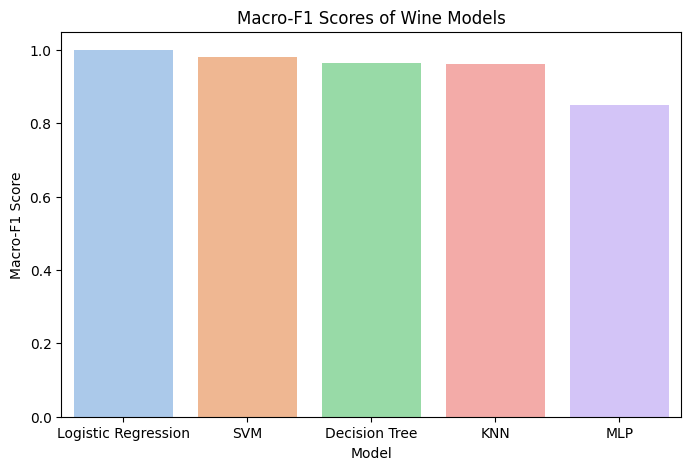

In [58]:
# Macro-F1 bar chart
### CODE HERE ###
results.sort_values(by='Macro-F1-Score', ascending=False, inplace=True)
plt.figure(figsize=(8,5))
sns.barplot(x='Model', y='Macro-F1-Score', data=results, palette='pastel')
plt.title('Macro-F1 Scores of Wine Models')
plt.xlabel('Model')
plt.ylabel('Macro-F1 Score')
plt.show()

### 5.3 Cross-Validation Stability <font color="red">[3 marks]</font>

For **all five models**, run 5-fold cross-validation with `scoring='f1_macro'` on the training set. Print the mean and standard deviation for each.


In [59]:
# Cross-validation stability for all 5 wine models
### CODE HERE ###
#Make
models = {'Logistic Regression' : best_model_lr_wd, 'KNN': best_knn_model_wd, 'Decision Tree': best_dt_model_wd, 'SVM': best_svm_model_wd, 'MLP':best_mlp_model_wd}
for model_name, model in models.items():
    scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='f1_macro')
    print(f"{model_name} - Mean F1-Score: {scores.mean():.4f}, Std Dev: {scores.std():.4f}")



Logistic Regression - Mean F1-Score: 0.9834, Std Dev: 0.0203
KNN - Mean F1-Score: 0.9776, Std Dev: 0.0184
Decision Tree - Mean F1-Score: 0.8800, Std Dev: 0.0772
SVM - Mean F1-Score: 0.9920, Std Dev: 0.0159
MLP - Mean F1-Score: 0.9136, Std Dev: 0.0591


### ✍️ Classical vs Neural Comparison

**[Your Answer]:**
1. Which classical model performed best on macro-F1? Why might that be?
2. Did the MLP beat the classical models by a clear margin, or was the gap small?
3. When would you choose a simpler model like Logistic Regression over the MLP, even if the MLP scores slightly higher?


*Write your answers here:*

1. Support Vecot Machine performed better than other classical models. From best paramters , we can understand that kernel for the SVC is RBF. With many checmical data , these features are well seggregated in hyperplane not in linear way. So it performed well

2. I rather need to check this , as my MLP model is not beating other chemical models , even though came out from grid search cv. Even Standard deviation is also high in this model.

3. I think , I will choose liner regression when we need speed , reliability and knowledge of bias and intercept. AS LR gives direct mathematical equation ( y - mx+c) whereas MLP is blackbox. Specially when dataset is small - LR will be a good idea. Else MLP will try to memorise with its complex black box hidden layer and weight. Also LR can run fast in CPU too.


## Stage 6: Final Recommendation

<font color="red">**[5 marks]**</font>


### 6.1 Final Model Selection <font color="red">[3 marks]</font>

**[Your Answer]:**
1. Which model do you recommend as the best **classical** model for the wine dataset? Cite its macro-F1 score.
2. Which model do you recommend as the best **overall** model? Consider performance vs interpretability.
3. If a winemaker wanted to understand *why* a wine was classified as a certain cultivar, which model would you recommend and why?


*Write your answers here:*

1. I will recommend for Support vecor machine( SVC Classifier ) , as its macro F1 score(.992) in highest in training set and lowest stndard deviation. Even on unknown test set too , it performed well with 2nd best F1 score(.98)

2. If we need to choose for performance and omterpretability point of view , then Logistic regression will be good option. SVM beats logistic regression in performance by a small mergin but we can get very transperent data from Logistic regression. We can find out co-efficient feature wise
A standard devistion .0303 shows its highly stable across different data folds.

3. As mentioned above , Logistic regression will be good fit for wine maker if wanted to understand why a wine was classified in a particular class. First It is visually explained and also easy data explaination. Decision tree also can be one choice , but here , it has less F1 score.
Logistic regression can be seen here as recipe , explaing which checmical properties and probabilities behind every decision


In [60]:
coefficients = best_model_lr_wd.coef_
print(coefficients.shape)
feature_names = wine_features.columns
coefficients_df = pd.DataFrame(coefficients, columns=feature_names, index=wine_data.target_names)
coefficients_df.head()


(3, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
class_0,0.413802,0.006088,0.189271,-0.396541,0.077123,0.234580,0.368400,-0.086631,0.019684,0.079424,0.087295,0.284549,0.506685
class_1,-0.523708,-0.211635,-0.346491,0.259521,-0.106092,-0.034953,0.064245,-0.025864,0.227774,-0.461106,0.303491,0.098516,-0.467115
class_2,0.109906,0.205547,0.157219,0.137020,0.028969,-0.199627,-0.432645,0.112495,-0.247459,0.381682,-0.390786,-0.383065,-0.039570


### 6.2 Underfitting vs Overfitting Study <font color="red">[2 marks]</font>

Train three Decision Tree variants on the wine dataset:
1. `max_depth=1` with `random_state=42` (too simple, underfits)
2. `max_depth=None` with `random_state=42` (no constraints, overfits)
3. Your best tuned tree from Stage 4

For each, print the **training accuracy** and **test accuracy**. Look at the gap.


In [61]:
# Overfitting study: 3 Decision Tree variants
### CODE HERE ###

dt_model_lessDepth = DecisionTreeClassifier(max_depth = 1, random_state=42)
dt_model_moreDepth = DecisionTreeClassifier(max_depth = None, random_state=42)
dt_model_best = best_dt_model_wd

dt_model_lessDepth.fit(X_train_scaled, y_train)
dt_model_moreDepth.fit(X_train_scaled, y_train)
dt_model_best.fit(X_train_scaled, y_train)

y_pred_lessDepth = dt_model_lessDepth.predict(X_test_scaled)
y_pred_moreDepth = dt_model_moreDepth.predict(X_test_scaled)
y_pred_best = dt_model_best.predict(X_test_scaled)

print("Decision tree with max_depth = 1 ")
print(f"Training Accuracy: {dt_model_lessDepth.score(X_train_scaled, y_train)}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_lessDepth)}")
print("\n")
print("Decision tree with max_depth = None ")
print(f"Training Accuracy: {dt_model_moreDepth.score(X_train_scaled, y_train)}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_moreDepth)}")

print("\n")
print("Decision tree with best tuned parameters ")
print(f"Training Accuracy: {dt_model_best.score(X_train_scaled, y_train)}")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_best)}")

Decision tree with max_depth = 1 
Training Accuracy: 0.6612903225806451
Test Accuracy: 0.6111111111111112


Decision tree with max_depth = None 
Training Accuracy: 1.0
Test Accuracy: 0.9629629629629629


Decision tree with best tuned parameters 
Training Accuracy: 0.9919354838709677
Test Accuracy: 0.9629629629629629


### ✍️ Underfitting vs Overfitting

**[Your Answer]:**
1. Which variant underfits? How can you tell from the train/test accuracy?
2. Which variant overfits? What is the gap between train and test accuracy?
3. How does the tuned model sit between these two extremes?


*Write your answers here:*

1. Here , variant with max_depth=1  , is underfitting. Both training and test accuracy is less. It is the simplest DT possible , with one root node ( and 2 leaf node) for final prediction. THis may not be sufficient to categorize the data

2. Decision tree model max_depth = None ( the tree has no maximum limit on its depth and will grow until it completely satisfies other stopping criteria ) is overfitting case. It gives perfect training accuracy but not so good test accuracy. THere is 4% gap between them. With so many depth , this model is trying to memorize all, including noise , into training data - but fails that perfectly in test data.

3. Best model is ideal spot in between over/under fitting. It has good training accuracy. At the same time , test accuracy is also better than other 2 model variant


---
## Indicative Mark Summary

> **Reminder:** These marks are for self-assessment only. They do not count towards your final grade.

| Section | Topic | Marks |
|---------|-------|-------|
| **Part 1** | | **55** |
| Stage 1 | Data Loading | 3 |
| Stage 2 | Data Understanding + Interpretation | 8 |
| Stage 3 | Preprocessing | 7 |
| Helper + Tutorial | Evaluation Function, GridSearchCV Walkthrough | 0 |
| Stage 4 | Model Training and Tuning (4 models) | 23 |
| Stage 5 | Model Comparison + Feature Importance | 9 |
| Stage 6 | Final Model Selection | 5 |
| **Part 2** | | **45** |
| Stage 1 | Data Loading | 2 |
| Stage 2 | Data Understanding + Interpretation | 6 |
| Stage 3 | Preprocessing | 4 |
| Stage 4 | Model Training and Tuning (5 models, incl. MLP) | 20 |
| Stage 5 | Model Comparison | 8 |
| Stage 6 | Final Recommendation | 5 |
| | **Total** | **100** |

---
*End of Practice Assignment*
